# Exercício: Pandas, NumPy e Matplotlib

**Objetivo:**
1. Criar um dicionário que armazene diferentes distribuições e seus parâmetros  
2. Simular dados usando `numpy.random`  
3. Calcular estatísticas básicas  
4. Plotar histogramas com `Matplotlib`  
5. Organizar as estatísticas em um `DataFrame` do `Pandas`  
6. Estender o exercício com novas distribuições e estatísticas adicionais  
7. Comparar resultados originais e aproximados  

---

## Passo 1 – Criar o dicionário principal
As chaves devem ser nomes de distribuições: `"Normal"`, `"Exponencial"`, `"Uniforme"`  
Os valores devem ser dicionários contendo:  
- `"params"` → parâmetros da distribuição  
- `"dados"` → inicialmente `None`  
- `"estatisticas"` → inicialmente `None`  

Exemplo de estrutura:

    distribuicoes = {
        "Normal": {"params": {"loc": 0, "scale": 1}, "dados": None, "estatisticas": None},
        "Exponencial": {"params": {"scale": 2}, "dados": None, "estatisticas": None},
        "Uniforme": {"params": {"low": -1, "high": 1}, "dados": None, "estatisticas": None}
    }

---

In [ ]:
distribuicoes = {
    "Normal": {"params": {"loc": 0, "scale": 1}, "dados": None, "estatisticas": None},
    "Exponencial": {"params": {"scale": 2}, "dados": None, "estatisticas": None},
    "Uniforme": {"params": {"low": -1, "high": 1}, "dados": None, "estatisticas": None}
}

## Passo 2 – Importar bibliotecas
Importe as bibliotecas:  
- `numpy` para simulação  
- `pandas` para organização dos resultados  
- `matplotlib` para visualização  

---

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

## Passo 3 – Gerar os dados
Para cada distribuição, gere uma amostra de tamanho **1000** usando `numpy.random` e salve em `"dados"`.  

---

In [ ]:
size_distribuicoes = 1000

distribuicoes["Normal"]["dados"] = np.random.normal(loc=distribuicoes["Normal"]["params"]["loc"], scale=distribuicoes["Normal"]["params"]["scale"], size=(size_distribuicoes))
distribuicoes["Exponencial"]["dados"] = np.random.exponential(scale=distribuicoes["Exponencial"]["params"]["scale"], size=(size_distribuicoes))
distribuicoes["Uniforme"]["dados"] = np.random.uniform(low=distribuicoes["Uniforme"]["params"]["low"], high=distribuicoes["Uniforme"]["params"]["high"], size=(size_distribuicoes))

## Passo 4 – Calcular estatísticas básicas
Para cada distribuição, calcule:  
- Média  
- Mediana  
- Variância  
- Desvio padrão  
Armazene em um dicionário dentro da chave `"estatisticas"`.  

---

In [ ]:
def calculaEstatisticas(distrib): # distrib é o dicionário de distribuições | essa função é vazia (void); apenas atualiza o dicionário parâmetro
  for dist in distrib:
      estatisticas = {
          "Média": np.mean(distrib[dist]["dados"]),
          "Mediana": np.median(distrib[dist]["dados"]),
          "Variância": np.var(distrib[dist]["dados"]),
          "Desvio Padrão": np.std(distrib[dist]["dados"])
      }
      distrib[dist]["estatisticas"] = estatisticas

calculaEstatisticas(distribuicoes)

## Passo 5 – Visualizar os dados
Para cada distribuição, faça um **histograma** mostrando a forma da distribuição.  

---

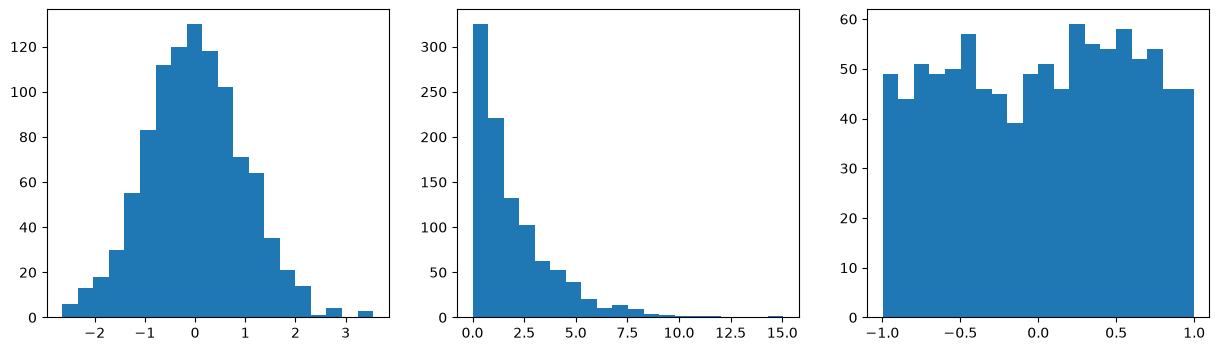

In [ ]:
barras_histograma = 20

fig, axs = plt.subplots(1, 3, figsize=(15, 4), sharey=False)
axs[0].hist(distribuicoes["Normal"]["dados"], bins=barras_histograma)
axs[1].hist(distribuicoes["Exponencial"]["dados"], bins=barras_histograma)
axs[2].hist(distribuicoes["Uniforme"]["dados"], bins=barras_histograma)

plt.show()

## Passo 6 – Organizar resultados em Pandas
Crie um `DataFrame` contendo as estatísticas de todas as distribuições.  

---

In [ ]:
def distribToDataFrame(dist): # Função para transformar o dicionário em um dataframe contendo as estatísticas de maneira dinâmica (não hardcoded)
  new_dict = {}
  for d in dist:
    new_dict[d] = dist[d]["estatisticas"]
  return pd.DataFrame(new_dict)


df_estatisticas = distribToDataFrame(distribuicoes)

print(df_estatisticas)

                 Normal  Exponencial  Uniforme
Média          0.005202     1.968855  0.015108
Mediana       -0.000775     1.312738  0.038988
Variância      0.934088     3.892159  0.328171
Desvio Padrão  0.966482     1.972856  0.572862


## Passo 7 – Adicionar novas distribuições
- Inclua mais uma distribuição, como `"Poisson"` ou `"Binomial"`.  
- Gere dados usando `numpy.random`.  
- Calcule as estatísticas básicas e atualize o `DataFrame`.  

---

In [ ]:
distribuicoes["Binomial"] = {"params": {"n": 50, "p": 0.5}, "dados": None, "estatisticas": None}

distribuicoes["Binomial"]["dados"] = np.random.binomial(n=distribuicoes["Binomial"]["params"]["n"], p = distribuicoes["Binomial"]["params"]["p"],  size=(size_distribuicoes)) # TODO: essa atribuição de parâmetros pode ser melhor executada

calculaEstatisticas(distribuicoes)
df_estatisticas = distribToDataFrame(distribuicoes)
print(df_estatisticas)

                 Normal  Exponencial  Uniforme   Binomial
Média          0.005202     1.968855  0.015108  25.046000
Mediana       -0.000775     1.312738  0.038988  25.000000
Variância      0.934088     3.892159  0.328171  12.539884
Desvio Padrão  0.966482     1.972856  0.572862   3.541170


## Passo 8 – Estatísticas adicionais
Para cada distribuição, calcule também:  
- Mínimo (`np.min`)  
- Máximo (`np.max`)  
- Quartis (`np.percentile`)  

Atualize o campo `"estatisticas"` e o `DataFrame` com essas novas colunas.  

---

In [ ]:
for dist in distribuicoes:
  extra_estatisticas = {
      "Mínimo": np.min(distribuicoes[dist]["dados"]),
      "Máximo": np.max(distribuicoes[dist]["dados"]),
      "Quartis": np.percentile(distribuicoes[dist]["dados"], [25, 50, 75])
  }
  distribuicoes[dist]["estatisticas"].update(extra_estatisticas)
  #pd.concat(df_estatisticas, pd.DataFrame({dist: extra_estatisticas})) #TODO: Forma de adicionar linhas em um DF

df_estatisticas = distribToDataFrame(distribuicoes)
print(df_estatisticas)

                                                          Normal  \
Média                                                   0.005202   
Mediana                                                -0.000775   
Variância                                               0.934088   
Desvio Padrão                                           0.966482   
Mínimo                                                 -2.646108   
Máximo                                                   3.54716   
Quartis        [-0.6341161670058267, -0.0007751266233123635, ...   

                                                     Exponencial  \
Média                                                   1.968855   
Mediana                                                 1.312738   
Variância                                               3.892159   
Desvio Padrão                                           1.972856   
Mínimo                                                  0.002191   
Máximo                                         

## Passo 9 – Comparar distribuições graficamente
Faça um **boxplot** com todas as distribuições no mesmo gráfico, com título e rótulos adequados.  

---

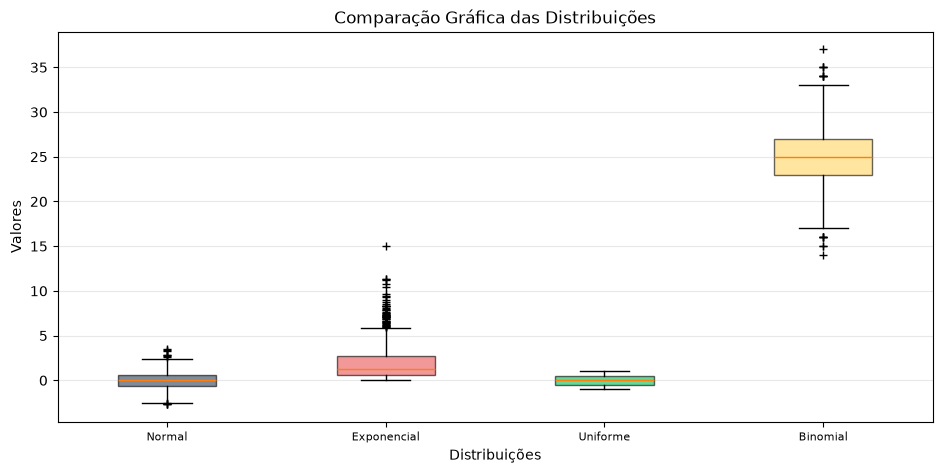

In [ ]:
# Referência: https://matplotlib.org/stable/gallery/statistics/boxplot_demo.html
fig, ax1 = plt.subplots(figsize=(10, 6))
fig.canvas.manager.set_window_title('Comparação de Distribuições')
fig.subplots_adjust(left=0.075, right=0.95, top=0.9, bottom=0.25)

data = [dist["dados"] for dist in distribuicoes.values()]
num_boxes = len(data)
cores = ["#2D4059", "#EA5455", "#00BD56", "#FFD460"] #hardcoded mesmo

bp = ax1.boxplot(data, notch=False, sym='+', orientation='vertical', whis=1.5, patch_artist=True)
plt.setp(bp['boxes'], color='black')
plt.setp(bp['whiskers'], color='black')
plt.setp(bp['fliers'], color='red', marker='+')

# linha horizontal para melhor leitura dos valores críticos do boxplot
ax1.yaxis.grid(True, linestyle='-', which='major', color='lightgrey',
               alpha=0.5)

ax1.set(
    axisbelow=True,  # grid atrás das boxes
    title='Comparação Gráfica das Distribuições',
    xlabel='Distribuições',
    ylabel='Valores',
)

# cores :)
for i in range(num_boxes):
    bp["boxes"][i].set_facecolor(cores[i])
    bp["boxes"][i].set_edgecolor('black')
    bp["boxes"][i].set_alpha(0.6)
# legendas para cada box
ax1.set_xticklabels(distribuicoes.keys(), fontsize=8)

plt.show()

## Passo 10 – Comparar estatísticas calculadas com valores teóricos
- Para cada distribuição, obtenha os valores teóricos (esperados) a partir dos parâmetros em `"params"`.  
- Compare esses valores com as estatísticas calculadas a partir da amostra.   
- Crie um gráfico de barras mostrando `media_teorica` e `media_amostra` para cada distribuição.  

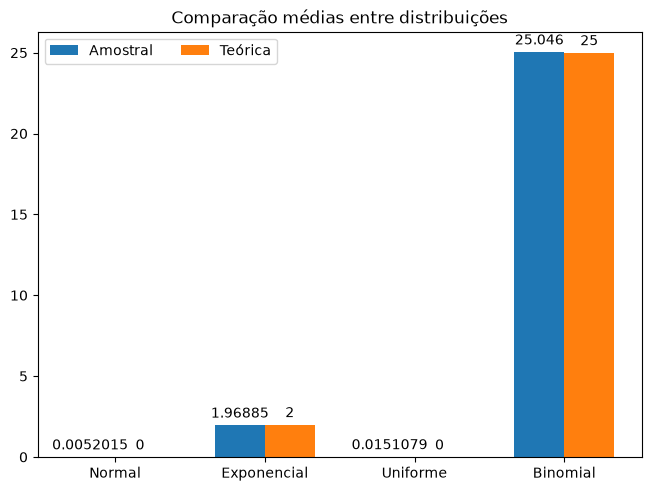

In [ ]:
distribuicoes["Normal"]["estatisticas"]["Média Teórica"] = distribuicoes["Normal"]["params"]["loc"]
distribuicoes["Exponencial"]["estatisticas"]["Média Teórica"] = distribuicoes["Exponencial"]["params"]["scale"]
distribuicoes["Uniforme"]["estatisticas"]["Média Teórica"] = (distribuicoes["Uniforme"]["params"]["low"] + distribuicoes["Uniforme"]["params"]["high"]) / 2
distribuicoes["Binomial"]["estatisticas"]["Média Teórica"] = distribuicoes["Binomial"]["params"]["n"] * distribuicoes["Binomial"]["params"]["p"]

nomes_distribuicoes = distribuicoes.keys()
medias = {"Amostral": [dist["estatisticas"]["Média"] for dist in distribuicoes.values()],
          "Teórica": [dist["estatisticas"]["Média Teórica"] for dist in distribuicoes.values()]}

fig, ax = plt.subplots(layout='constrained') # https://matplotlib.org/stable/gallery/lines_bars_and_markers/barchart.html
# grouped_bar é uma função nova da versão 3.11 do pyplot. para atualizar é só rodar: !pip install --upgrade matplotlib
res = ax.grouped_bar(medias, tick_labels=nomes_distribuicoes, group_spacing=1)
for container in res.bar_containers:
    ax.bar_label(container, padding=3)

ax.set_title('Comparação médias entre distribuições')
ax.legend(loc='upper left', ncols=3)
plt.show()